In [1]:
import keras
from keras.models import Sequential
from keras.layers import MaxPooling2D, Conv2D, Flatten, Dense, Dropout, BatchNormalization
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('dark_background')
from keras.utils import to_categorical
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [5]:
label_encoder = LabelEncoder()
label_encoder.fit(["cloudy", "foggy", "rainy", "shine", "sunrise"])
data =[]
labels=[]
for weather_folder in ["cloudy", "foggy", "rainy", "shine", "sunrise"]:
    class_index = label_encoder.transform([weather_folder])[0]
    class_label = to_categorical(class_index, num_classes=5)
    paths = []
    for r, d, f in os.walk(os.path.join(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather", weather_folder)):
        for file in f:
            if file.lower().endswith(('.jpg', '.jpeg')):
                paths.append(os.path.join(r, file))

        for path in paths:
            img = Image.open(path)
            img = img.resize((128, 128))
            img = np.array(img)
            if img.shape == (128, 128, 3):
                  data.append(img)
                  labels.append(class_label)
data = np.array(data)
labels = np.array(labels)

print(data.shape)
print(labels.shape)

(1504, 128, 128, 3)
(1504, 5)


In [6]:
data = np.array(data)
data.shape

(1504, 128, 128, 3)

In [7]:
result = np.array(labels)
result=result.reshape(1504, -1)

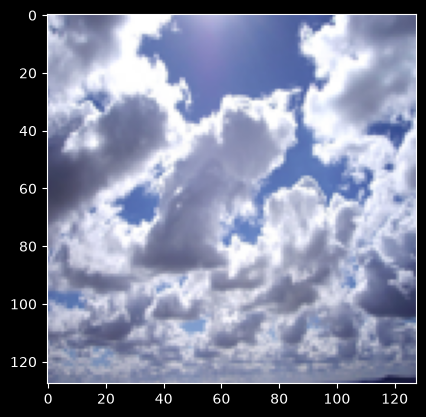

In [8]:
plt.imshow(data[10])

In [9]:
x_train,x_test,y_train,y_test = train_test_split(data,result, test_size=0.2, shuffle=True, random_state=42)

In [16]:
output_classes = 5

model = Sequential()

model.add(Conv2D(32, kernel_size=(2, 2), input_shape=(128, 128, 3), padding = 'Same'))
model.add(Conv2D(32, kernel_size=(2, 2),  activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    33,554,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,587,141 (128.12 MB)

 Trainable params: 33,586,949 (128.12 MB)

 Non-trainable params: 192 (768.00 B)

None


In [18]:
model.compile(loss = "categorical_crossentropy", optimizer='Adam',metrics=['accuracy'])

In [19]:
x_train.shape

(1203, 128, 128, 3)

In [20]:
y_train.shape

(1203, 5)

In [21]:
history = model.fit(x_train, y_train, epochs = 10, batch_size = 20, verbose = 1,validation_data = (x_test, y_test))

Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.5403 - loss: 14.4580 - val_accuracy: 0.5714 - val_loss: 3.0298
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.6542 - loss: 1.6921 - val_accuracy: 0.4086 - val_loss: 4.0645
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.7215 - loss: 0.9599 - val_accuracy: 0.4053 - val_loss: 5.3455
Epoch 4/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.7024 - loss: 1.0787 - val_accuracy: 0.4850 - val_loss: 3.3775
Epoch 5/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.7348 - loss: 0.8938 - val_accuracy: 0.3787 - val_loss: 3.7166
Epoch 6/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.7332 - loss: 0.7187 - val_accuracy: 0.4518 - val_loss: 3.7568
Epoch 7/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.7789 - loss: 0.6987 - val_accuracy: 0.3953 - val_loss: 5.1750
Epoch 8/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.7963 - loss: 0.5637 - val_accuracy: 0.3455 - val_

In [22]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 217ms/step - accuracy: 0.3223 - loss: 6.5564
Test Accuracy: 0.3222591280937195


In [23]:
def names(number):
    if number==0:
        return "cloudy"
    elif number==1:
        return "foggy"
    elif number==2:
        return "rainy"
    elif number==3:
        return "shine"
    else:
        return "sunrise"

99.35215% Confidence This Is foggy


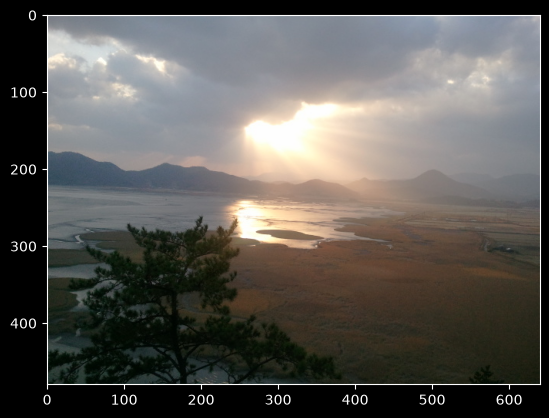

In [24]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather\cloudy\cloudy7.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

99.99922% Confidence This Is foggy


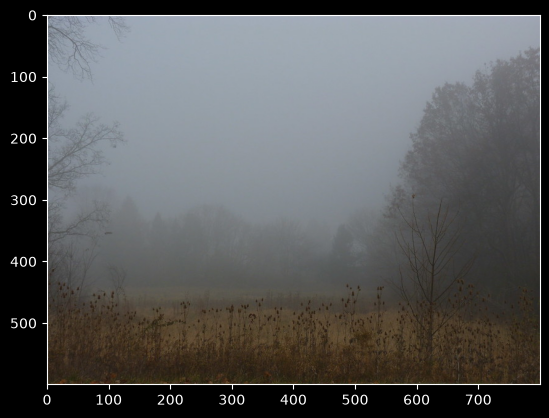

In [25]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather\foggy\foggy293.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

99.999954% Confidence This Is foggy


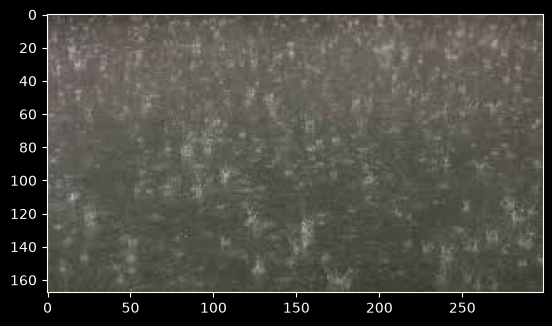

In [26]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather\rainy\rain6.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

87.04989% Confidence This Is foggy


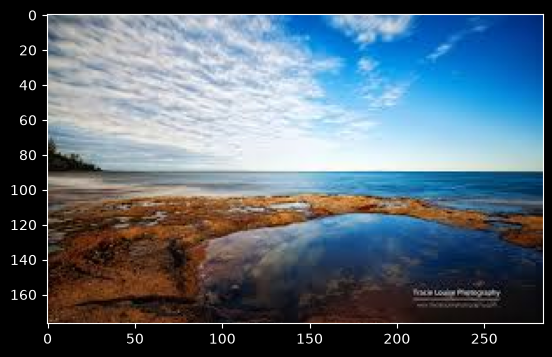

In [27]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather\shine\shine8.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

97.08026% Confidence This Is sunrise


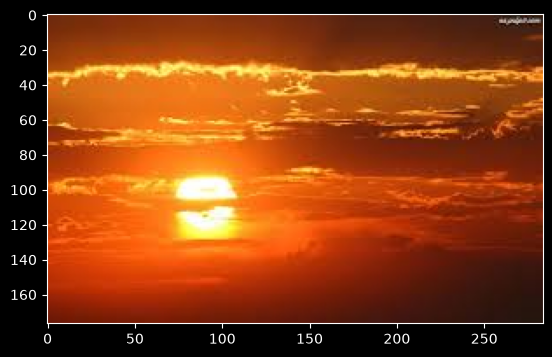

In [28]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple Weather\Multiple Weather\Multiple Weather\sunrise\sunrise17.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))